# Kaiser Permanente Nurse Staffing Optimization Engine
**Jesse Leyva · Final Project Phase 1**

A hypothetical 24-bed California medical-surgical unit, 22 RNs, 28 twelve-hour shifts and 100 common scenarios. Minimize **planned 14-day staffing cost ($)** and maximize **shift coverage without unplanned call-ins (%)**. This is a research simulation, not an actual Kaiser roster or clinical decision system.

Candidate generation preserves forecast coverage, availability, qualifications, a modeled 12-hour rest interval and 48-hour weekly cap. The assumed $125,000 budget is reported, not used to hide the unconstrained frontier. Scenario shortfalls require escalation; they do not authorize unsafe staffing. No Phase 2 decision-agent filtering is included.

## 1 Setup and reproducible data acquisition
Run from the repository root. The module is included in `src/engine.py`, with documented equations and the O(n log n) skyline implementation. Full AI design prompt and provenance: `docs/data_provenance.md`. All source values, pay rates, census and policy distributions are explicitly hypothetical. HCAI documentation provides context only; no facility-specific extract calibrated these values.

In [1]:
from pathlib import Path
import sys, json, platform, importlib.metadata
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = Path.cwd()
if not (ROOT / "src/engine.py").exists():
    raise RuntimeError("Open this notebook from the repository root")
from src.engine import run, pareto_mask, brute_pareto, OBJECTIVES, BUDGET
df, strategies, examples, summary, extremes, validation = run(ROOT)
print(f"Generated {len(df)} candidates with seed 42")
display(df.head())

Generated 100 candidates with seed 42


,candidate_id,roster_variant,extra_regular_shifts,regular_rn_shifts,float_rn_shifts,mean_float_per_shift,regular_hours,overtime_hours,float_hours,staffing_cost,...,coverage_ci_high,worst_scenario_coverage_pct,budget_met,baseline_coverage_met,pareto,cost_utility,coverage_utility,balanced_score,equity_gap,weighted_score
0,P001,0,0,143,0,0.000000,1584,132,0,106920.0,...,54.412567,32.142857,True,True,False,100.000000,0.000000,100.000000,100.000000,30.000000
1,P002,0,0,143,4,0.142857,1584,132,48,112200.0,...,60.192687,39.285714,True,True,False,85.135135,18.081588,103.216723,67.053547,38.197652
2,P003,0,0,143,8,0.285714,1584,132,96,117480.0,...,65.535686,46.428571,True,True,False,70.270270,34.619625,104.889895,35.650645,45.314819
3,P004,0,0,143,14,0.500000,1584,132,168,125400.0,...,72.974754,53.571429,False,True,False,47.972973,58.103638,106.076611,10.130665,55.064439
4,P005,0,0,143,22,0.785714,1584,132,264,135960.0,...,83.318047,57.142857,False,True,False,18.243243,90.628445,108.871689,72.385202,68.912885


## 2 Data quality and exploration
Candidate rows (100) are distinct from the supporting scenario-shift rows (2,800). Validation checks missingness, finite numeric types, IDs, bounds, integral counts, roster coverage, availability, rest, weekly caps and independent recomputation of cost and reliability for all 100 candidates. The approximate 95% coverage intervals use 100 independent scenario-level averages to retain within-scenario correlation.

rows                                                                                100
missing_cells                                                                         0
dtypes                                {'candidate_id': 'object', 'roster_variant': '...
candidate_duplicates                                                                  0
distinct_full_assignment_decisions                                                  100
observed_census_mean                                                          17.973214
absence_rate                                                                   0.049302
mandatory_roster_checks                                                    100/100 pass
cost_recalculation                                                         100/100 pass
coverage_recalculation                                                     100/100 pass
budget_met_count                                                                     60
scope                           

,count,mean,std,min,25%,50%,75%,max
roster_variant,100.0,9.500000,5.795331,0.000000,4.750000,9.500000,14.250000,19.000000
extra_regular_shifts,100.0,2.850000,1.940400,0.000000,1.000000,3.000000,4.250000,6.000000
regular_rn_shifts,100.0,145.850000,1.940400,143.000000,144.000000,146.000000,147.250000,149.000000
float_rn_shifts,100.0,9.600000,7.774603,0.000000,4.000000,8.000000,14.000000,22.000000
mean_float_per_shift,100.0,0.342857,0.277664,0.000000,0.142857,0.285714,0.500000,0.785714
regular_hours,100.0,1584.000000,0.000000,1584.000000,1584.000000,1584.000000,1584.000000,1584.000000
overtime_hours,100.0,166.200000,23.284798,132.000000,144.000000,168.000000,183.000000,204.000000
float_hours,100.0,115.200000,93.295230,0.000000,48.000000,96.000000,168.000000,264.000000
staffing_cost,100.0,122670.000000,10474.257622,106920.000000,113400.000000,120720.000000,129990.000000,142440.000000
coverage_pct,100.0,67.933571,9.632097,52.535714,60.125000,65.767857,74.080357,84.928571


,dtype
candidate_id,object
roster_variant,int64
extra_regular_shifts,int64
regular_rn_shifts,int64
float_rn_shifts,int64
mean_float_per_shift,float64
regular_hours,int64
overtime_hours,int64
float_hours,int64
staffing_cost,float64


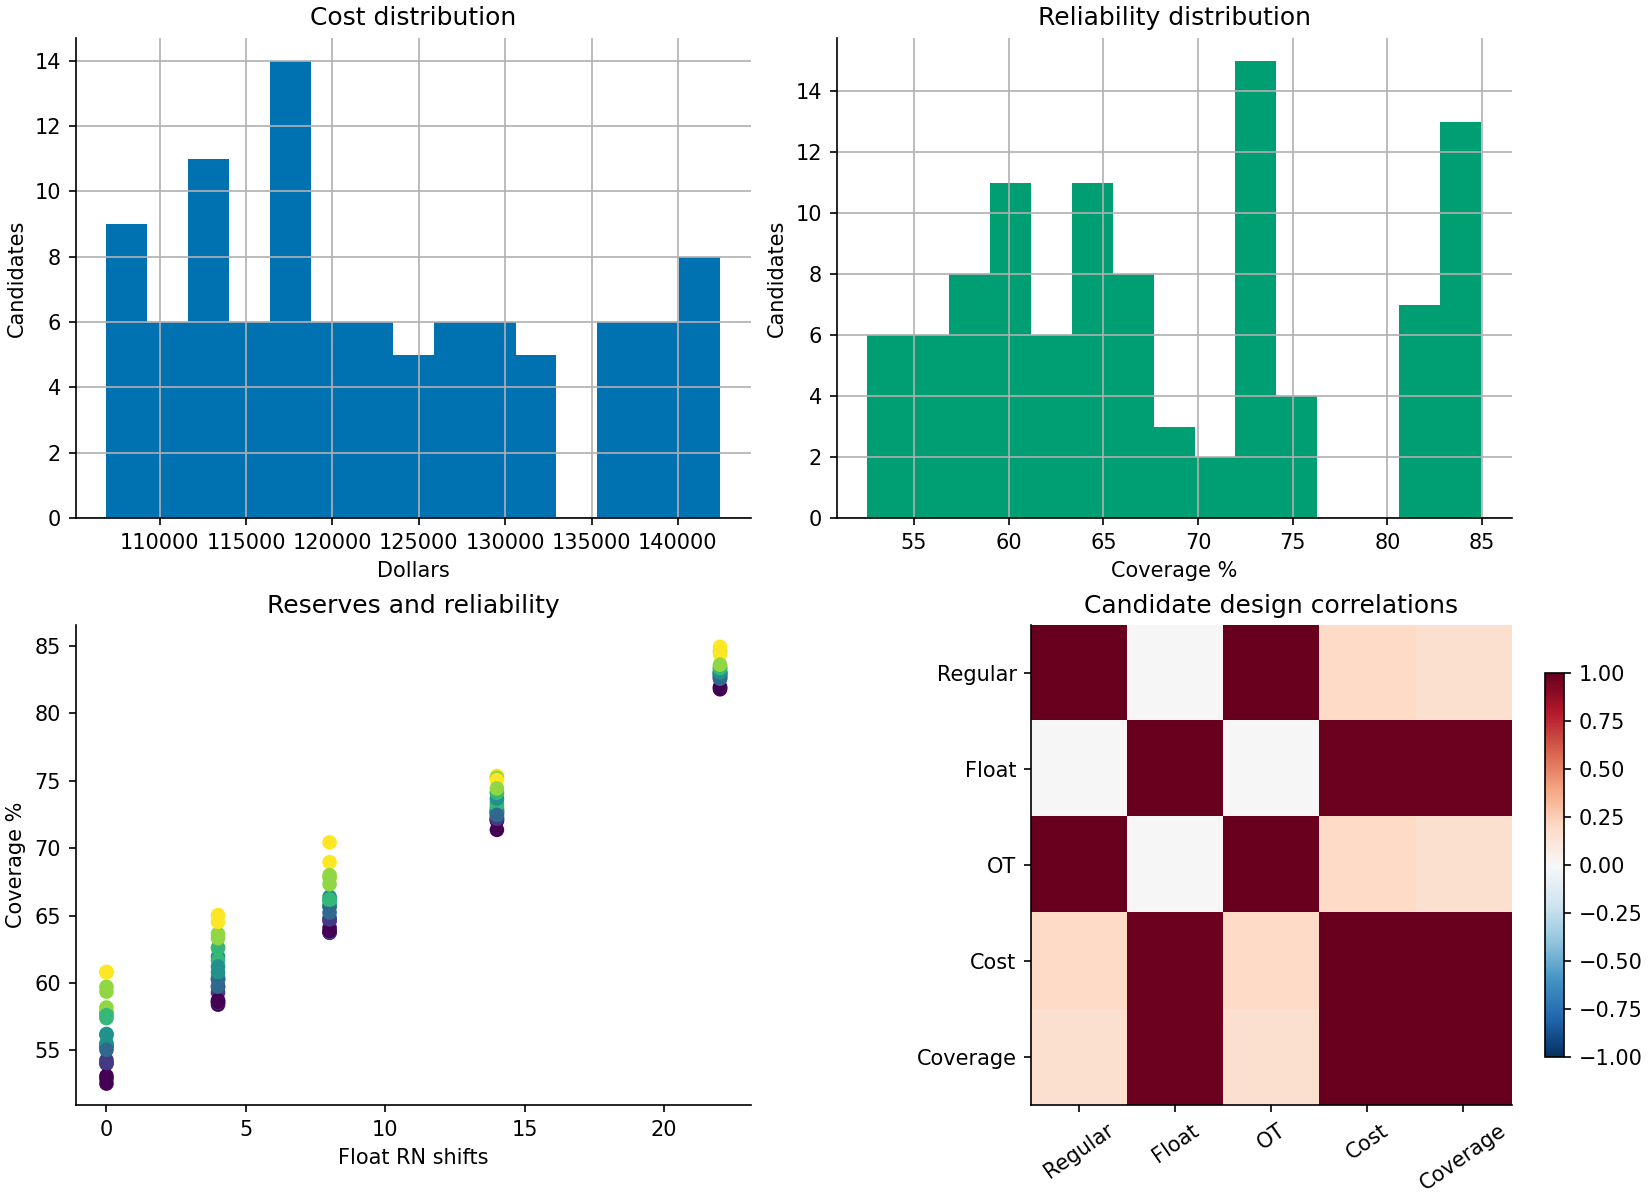

In [2]:
display(pd.Series(validation, name="Validation result"))
display(df.describe().T)
display(df.dtypes.rename("dtype").to_frame())
display(Image(filename=str(ROOT / "images/exploration.png")))

## 3 Pareto frontier
A dominates B when cost(A) ≤ cost(B) and coverage(A) ≥ coverage(B), with at least one strict inequality. Improvement in **both** is not necessary for dominance. The skyline sorts cost ascending and reliability descending, processes equal-cost groups, and retains exact duplicate efficient objective pairs. Empty inputs, negative values and ties are handled; nonfinite inputs are rejected. `tests/test_engine.py` compares the skyline against an independent quadratic oracle in all four objective directions.

This frontier is exact among the 100 sampled candidates, not a proof of globally optimal binary nurse assignments.

In [3]:
assert np.array_equal(df.pareto.to_numpy(), brute_pareto(df[OBJECTIVES].to_numpy()))
print(f"Efficient: {int(df.pareto.sum())}; dominated: {int((~df.pareto).sum())}")
display(summary)
display(df[df.pareto].sort_values("staffing_cost")[["candidate_id", "staffing_cost", "coverage_pct", "budget_met"]])

Efficient: 30; dominated: 70


staffing_cost                                         coverage_pct  \
               count       min    median      mean       max        count   
pareto                                                                      
False             70  106920.0  120180.0  122472.0  142440.0           70   
True              30  106920.0  121800.0  123132.0  142440.0           30   

                                                   float_rn_shifts             \
              min     median       mean        max           count min median   
pareto                                                                          
False   52.535714  65.464286  67.591837  84.392857              70   0    8.0   
True    53.107143  67.196429  68.730952  84.928571              30   0    8.0   

                     overtime_hours                               
            mean max          count  min median        mean  max  
pareto                                                            
False   9.514286  22             70  132  168.0  165.257143  204  
True    9.800000  22             30  132  168.0  168.400000  204

,candidate_id,staffing_cost,coverage_pct,budget_met
70,P071,106920.0,53.107143,True
40,P041,108000.0,54.285714,True
45,P046,109080.0,55.392857,True
85,P086,110160.0,56.214286,True
55,P056,111240.0,57.821429,True
71,P072,112200.0,58.714286,True
25,P026,112320.0,59.714286,True
30,P031,113400.0,60.821429,True
16,P017,115440.0,61.964286,True
91,P092,116520.0,62.607143,True


## 4 Dominated alternatives and scalar comparison
The examples below are stricter than the basic dominance definition: each alternative costs **less** and covers **more**. Savings exclude unplanned call-in costs. There is no unique best dominated or worst efficient point without choosing a ranking; the next table explicitly uses the normalized balanced score. A low-scoring frontier extreme is not necessarily dominated by a high-scoring inefficient plan.

In [4]:
display(examples)
display(extremes[["comparison", "candidate_id", "staffing_cost", "coverage_pct", "balanced_score"]])
assert len(examples) >= 3
assert (examples.cost_saving > 0).all() and (examples.coverage_gain_pp > 0).all()

,dominated,efficient_alternative,cost_saving,coverage_gain_pp
0,P050,P080,1080.0,0.107143
1,P015,P080,1080.0,0.107143
2,P085,P080,1080.0,0.428571
3,P027,P038,120.0,0.464286
4,P032,P078,120.0,0.178571


,comparison,candidate_id,staffing_cost,coverage_pct,balanced_score
4,Best dominated by balanced score,P005,135960.0,81.892857,108.871689
34,Lowest-scoring efficient by balanced score,P035,142440.0,84.928571,100.000000


## 5 Five strategic selections
Both benefits are mapped to 0–100 over the **same full-candidate anchors**: cost benefit = 100(max cost − cost)/(max cost − min cost); coverage benefit = 100(coverage − min coverage)/(max coverage − min coverage). The balanced strategy maximizes their sum, avoiding addition of dollars to percentages. Equity minimizes their absolute gap **on the frontier**, with balanced score then ID breaking ties. It is parity of modeled stakeholder benefits, not proof of equitable nurse workloads or patient outcomes. Priority strategies minimize raw cost or maximize raw coverage. Custom weighted = 30% cost benefit + 70% coverage benefit, prioritizing resilience. Identical selections are allowed: different strategies need not produce five distinct plans.

All selections are made on the full frontier. `budget_met` explicitly marks whether each meets the proposed ceiling; these are strategic reference points, not automatically deployable recommendations.

In [5]:
cols = ["strategy", "candidate_id", "regular_rn_shifts", "float_rn_shifts", "overtime_hours", "staffing_cost", "coverage_pct", "cost_utility", "coverage_utility", "budget_met"]
display(strategies[cols].round(3))
notes = {
 "Balanced": "Highest combined normalized cost and reliability benefit; budget must still be checked.",
 "Equity": "Closest parity between normalized finance and coverage benefits; not individual nurse fairness.",
 "Cost priority": "Lowest planned spending among efficient plans; higher reliance on unplanned escalation.",
 "Coverage priority": "Highest simulated no-call-in reliability; expensive reserves may exceed the ceiling.",
 "Coverage weighted 70%": "Resilience receives 70% of utility weight; can coincide with balanced selection."
}
for _, row in strategies.iterrows():
    print(f"{row['strategy']} ({row.candidate_id}): {notes[row['strategy']]}")

,strategy,candidate_id,regular_rn_shifts,float_rn_shifts,overtime_hours,staffing_cost,coverage_pct,cost_utility,coverage_utility,budget_met
79,Balanced,P080,144,22,144,137040.0,83.000,15.203,94.046,False
67,Equity,P068,149,8,204,123960.0,70.429,52.027,55.237,True
70,Cost priority,P071,143,0,132,106920.0,53.107,100.000,1.764,True
34,Coverage priority,P035,149,22,204,142440.0,84.929,0.000,100.000,False
79,Coverage weighted 70%,P080,144,22,144,137040.0,83.000,15.203,94.046,False


Balanced (P080): Highest combined normalized cost and reliability benefit; budget must still be checked.
Equity (P068): Closest parity between normalized finance and coverage benefits; not individual nurse fairness.
Cost priority (P071): Lowest planned spending among efficient plans; higher reliance on unplanned escalation.
Coverage priority (P035): Highest simulated no-call-in reliability; expensive reserves may exceed the ceiling.
Coverage weighted 70% (P080): Resilience receives 70% of utility weight; can coincide with balanced selection.


## 6 Executive tradeoff visualization
Panel 1 projects 616 binary regular assignments and 28 integer reserve counts to two interpretable aggregate decision levers; overlapping points are possible. Panel 2 shows exact discrete candidate efficiency and strategy markers; the connecting guide is not a feasible continuous interpolation. Panel 3 shows descriptive group means by reserved float count, not a causal response curve. Current monetary and reliability axes remain in business units.

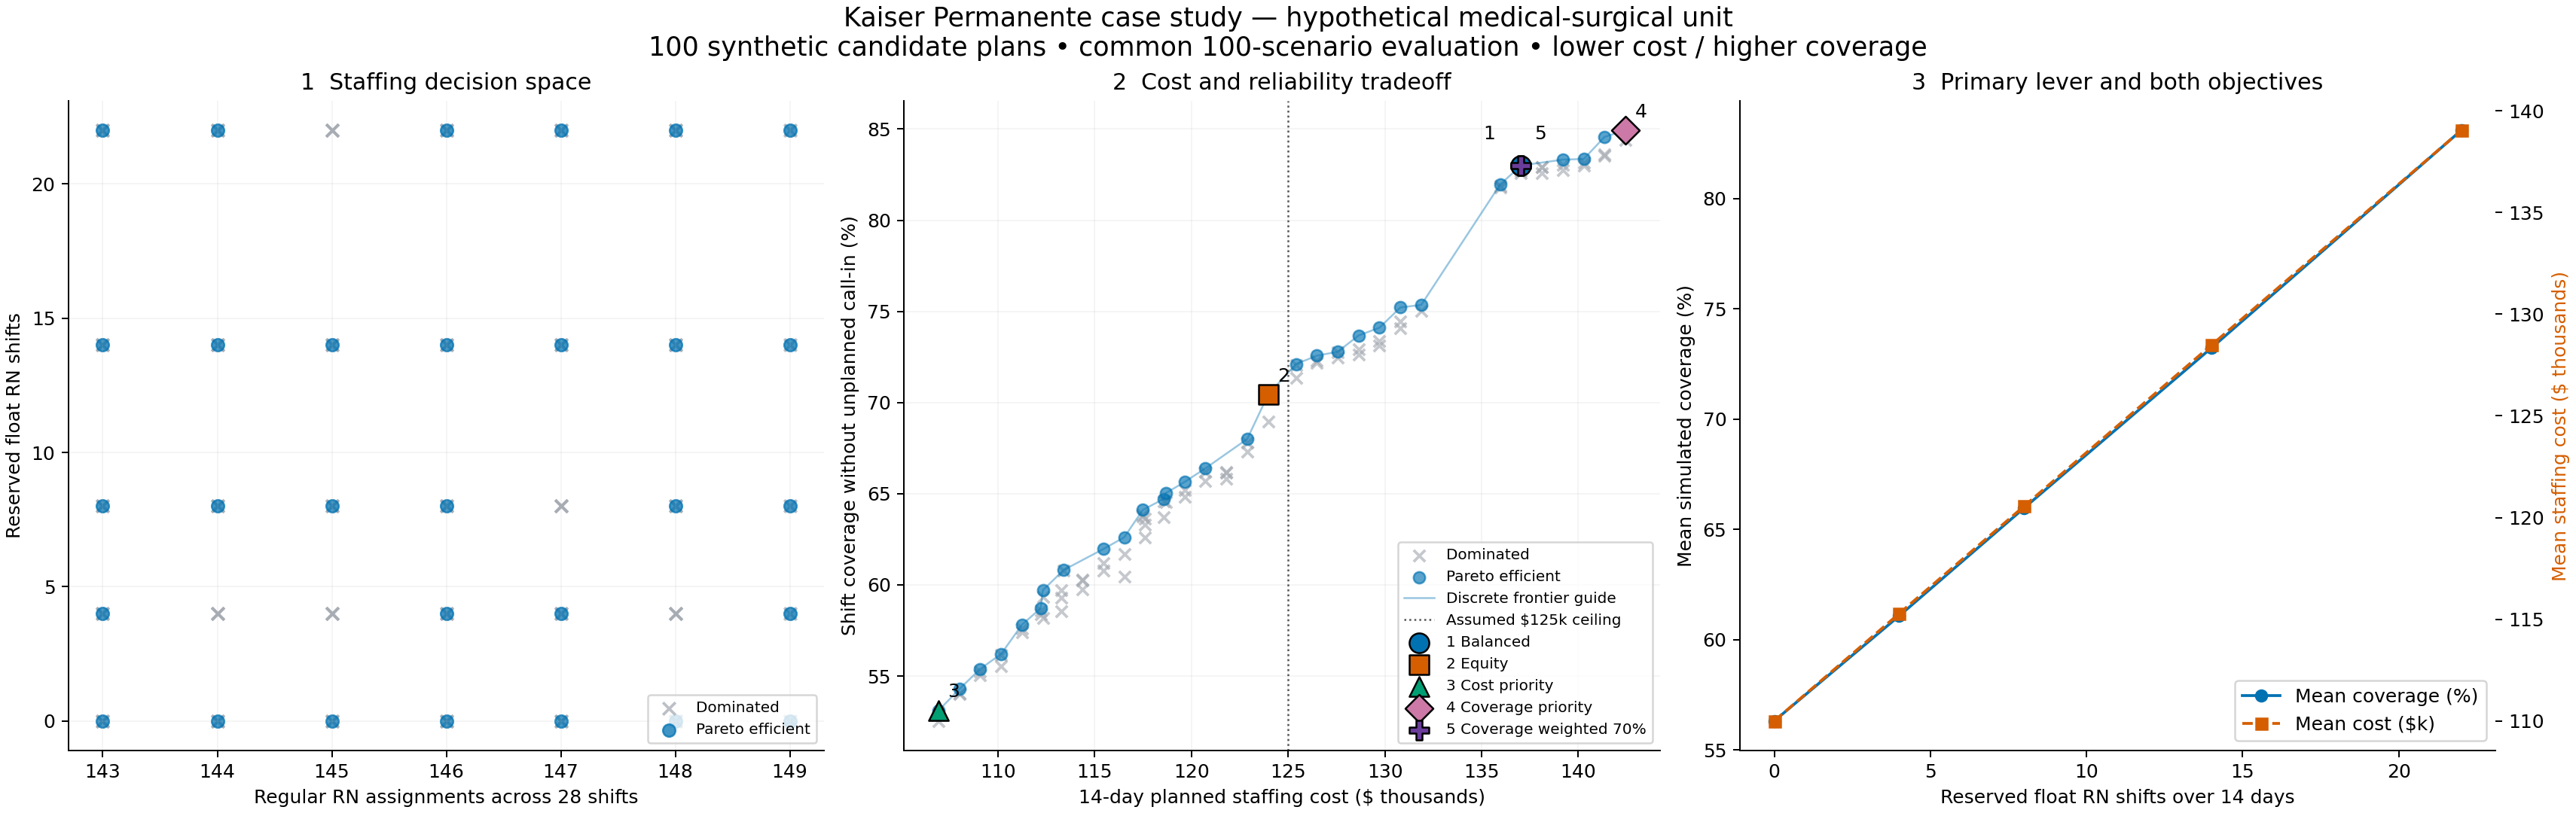

In [6]:
display(Image(filename=str(ROOT / "images/three_panel_analysis.png")))

## 7 Sensitivity and limitations
Vary each assumed hourly rate separately by ±20%, holding staffing and scenario outcomes fixed. This is cost sensitivity, not a new optimized roster or a general scenario-testing agent. Frontier membership is conditional on cost assumptions. No real clinical outcomes or real Kaiser savings are claimed.

In [7]:
display(pd.read_csv(ROOT / "results/rate_sensitivity.csv"))
base = df.iloc[0]
print(f"Fixed seed baseline {base.candidate_id}: ${base.staffing_cost:,.0f}; {base.coverage_pct:.2f}% coverage")
print(f"Plans under assumed budget: {int(df.budget_met.sum())} of {len(df)}")
print("Baseline capacity is covered; scenario shortfalls mean additional staffing escalation is required.")

,rate_varied,rate_factor,efficient_count,budget_met_count
0,regular,0.8,30,100
1,regular,1.0,30,60
2,regular,1.2,30,0
3,overtime,0.8,28,69
4,overtime,1.0,30,60
5,overtime,1.2,30,52
6,float,0.8,27,72
7,float,1.0,30,60
8,float,1.2,29,58


Fixed seed baseline P001: $106,920; 52.54% coverage
Plans under assumed budget: 60 of 100
Baseline capacity is covered; scenario shortfalls mean additional staffing escalation is required.


## 8 Findings and business implications
The exact figures are generated below rather than typed from memory. More reserved capacity generally improves robustness at a higher planned cost. Dominated alternatives demonstrate operational improvement opportunities in this sampled design. Budget conflicts must be resolved before Phase 2 recommendations. Priorities on a normalized frontier cannot replace mandatory staffing, contract, acuity or competency review.

Limitations: no HCAI facility calibration; no clinical validation; limited candidate sampling; dedicated day/night cohorts; approximate break relief; guaranteed qualified floats; simplified absences; no emergency replacement cost; no intrashift workload model. Shared scenarios support fair paired comparisons but strategies are selected on that same bank, so estimates can overfit and close differences may be Monte Carlo noise. Normalization and equity definitions are policy choices. A fresh scenario bank and clinical/operational review are future work.

In [8]:
balanced = strategies.iloc[0]
equity = strategies.iloc[1]
text = f"""**Run summary:** {int(df.pareto.sum())}/100 efficient candidates. Balanced: **{balanced.candidate_id}**, **${balanced.staffing_cost:,.0f}**, **{balanced.coverage_pct:.2f}%** coverage, budget met **{bool(balanced.budget_met)}**. Equity: **{equity.candidate_id}**, **${equity.staffing_cost:,.0f}**, **{equity.coverage_pct:.2f}%**, budget met **{bool(equity.budget_met)}**. All 100 rosters pass mandatory modeled checks; candidate feasibility under budget remains separately disclosed."""
display(Markdown(text))
manifest = {"python": platform.python_version(), "packages": {p: importlib.metadata.version(p) for p in ["numpy", "pandas", "scipy", "matplotlib", "nbformat", "nbclient", "ipykernel"]}, "seed": 42, "fresh_kernel_run": "completed all analysis cells", "candidate_count": len(df), "pareto_count": int(df.pareto.sum())}
(ROOT / "results/reproducibility.json").write_text(json.dumps(manifest, indent=2))

**Run summary:** 30/100 efficient candidates. Balanced: **P080**, **$137,040**, **83.00%** coverage, budget met **False**. Equity: **P068**, **$123,960**, **70.43%**, budget met **True**. All 100 rosters pass mandatory modeled checks; candidate feasibility under budget remains separately disclosed.

335

## Sources
- Approved user proposal: *Nurse Staffing Cost and Coverage at Kaiser Permanente* (Jesse Leyva).
- [CDPH AFL 07-26](https://www.cdph.ca.gov/Programs/CHCQ/LCP/Pages/AFL-07-26.aspx), historical staffing ratio and acuity context.
- [AHRQ Nursing and Patient Safety](https://psnet.ahrq.gov/primer/nursing-and-patient-safety), staffing complexity.
- [HCAI Hospital Utilization](https://hcai.ca.gov/data/healthcare-utilization/hospital-utilization/), annual dataset documentation. Documentation reviewed; no numerical calibration claimed.
- Full prompt, assumptions, versions and limitations are in the repository documentation and results files.